# Lab 1 · Which model catches more fake-labelled notes?

Start with a practical choice. Missing a fake is costly, but flagging a real note also creates work. Compare both errors before choosing a model. You will read the split, compare four classifiers, then inspect photographs where two of them disagree.

**Result to check.** EfficientNetV2-S caught **93.06%** of fake-labelled notes on the expanded test set and flagged **13.33%** of real notes. In Section 2, compare its recall with ResNet18 and its false alarms with DINOv3. Section 3 tests how the ranking changes when the photographs change.

Run the cells in order from the project directory. The appendix holds the training code and optional exercises. [Image roster](dataset_archive_course_v3/image_paths.csv) · [Per-seed results](runs/course_models_archive_v3/comparison.csv)

In [1]:
import csv
import gc
import hashlib
import json
import random
import time
from pathlib import Path
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from matplotlib.figure import Figure
from PIL import Image, ImageEnhance
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision.models import (
    EfficientNet_V2_S_Weights, ResNet18_Weights, efficientnet_v2_s, resnet18,
)

# Only the DINOv3 experiment uses timm.
try:
    import timm
except ModuleNotFoundError as error:
    if error.name != "timm":
        raise
    timm = None

In [2]:
DATA = Path("dataset_archive_course_v3")
PILOT_DATA = Path("dataset_archive_pilot_v2")
RESNET = Path("runs/archive_pilot_v2/resnet18/best.pt")
COMPARISON = Path("runs/course_models_archive_v3")
RUN_COMPARISON = True
SEED = 42
BATCH_SIZE = 32
DEMO_EPOCHS = 3

EPOCHS = 30
LR = 1e-3
CLASS_NAMES = ["fake money", "OR money"]
THREE_CLASS_NAMES = CLASS_NAMES + ["not a banknote"]
DISPLAY_NAMES = {"fake money": "Fake Money", "OR money": "Real Money", "not a banknote": "Not a Banknote"}
FAKE_THRESHOLD = 0.5  # Fixed threshold; tune only on validation data if needed.
TRANSFER_MODELS = ("resnet18", "efficientnet_v2_s", "dinov3_vits16")
DINO_TIMM_MODEL = "vit_small_patch16_dinov3.lvd1689m"


MODEL_NAMES = {"cnn": "CNN", "resnet18": "ResNet18", "efficientnet_v2_s": "EfficientNetV2-S",
               "dinov3_vits16": "DINOv3 ViT-S/16"}
METRICS = ["accuracy", "balanced_accuracy", "fake_recall", "fake_fnr", "fake_precision",
           "real_false_alarm_rate", "not_banknote_recall", "not_banknote_as_fake_rate"]

## 1. Count the photographs and inspect one per class

Start with the **test** column. How many mistakes would change fake recall by about four percentage points? There are 24 fake-labelled notes, so one missed fake changes recall by $100/24 = 4.17$ percentage points in a single run.

Use the three photographs to check what each folder contains. `OR money` is the real-labelled class. The source path points into the archive or earlier non-banknote collection. The model-input path points into `dataset_archive_course_v3/{train,val,test}/<class>/`. The photos below show the original frame. Training resizes and pads it to a square.

One representative was selected per eligible filename family, with rotation/flip-aware near-duplicate screening. The 30 non-banknotes come from the previous split. Folder labels and physical identities remain unverified. [Split manifest](dataset_archive_course_v3/manifest.json) · [Selection code](dataset_archive_course_v3/prepare_split.py)

split,train,val,test
Folder label,,,
Fake Money,83,17,24
Not a Banknote,22,4,4
Real Money,82,17,25


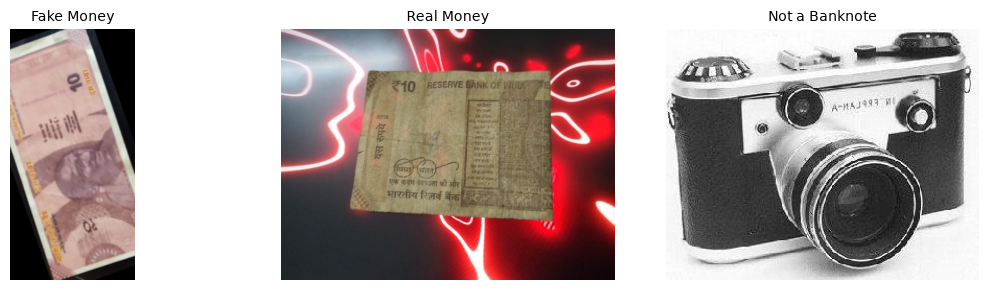

,Folder label,source_path,Model input file
0,Fake Money,archive/data/data/fake/10/aug_395_WhatsApp Image 2025-04-05 at 10.55.45.jpeg,dataset_archive_course_v3/train/fake money/10_3013738dc9732936.jpeg
124,Real Money,archive/data/data/real/10/IMG_1667843664629.jpg,dataset_archive_course_v3/train/OR money/10_9b1ec45648e42474.jpg
248,Not a Banknote,dataset_archive_pilot_v2/train/not a banknote/camera_image_0045.jpg,dataset_archive_course_v3/train/not a banknote/camera_image_0045.jpg


In [3]:
def show_photos(files, captions):
    """Display each original photograph beside its supplied class or prediction caption."""
    fig, axes = plt.subplots(1, len(files), figsize=(3.8 * len(files), 3), squeeze=False)
    for ax, path, caption in zip(axes[0], files, captions):
        with Image.open(path) as image:
            ax.imshow(image.convert("RGB"))
        ax.set_title(caption, fontsize=10)
        ax.axis("off")
    fig.tight_layout()
    plt.show()

paths = pd.read_csv(DATA / "image_paths.csv", keep_default_na=False)
paths["Folder label"] = paths["label"].map(DISPLAY_NAMES)
paths["Model input file"] = paths["split_path"].map(lambda p: str(DATA / p))
names = list(DISPLAY_NAMES.values())
display(pd.crosstab(paths["Folder label"], paths["split"])[["train", "val", "test"]])

examples = paths[paths["split"] == "train"].drop_duplicates("label")
show_photos(examples["Model input file"], examples["Folder label"])
with pd.option_context("display.max_colwidth", None):
    display(examples[["Folder label", "source_path", "Model input file"]])

## 2. Compare the models on the same 53 test photographs

The CNN learns from scratch on 64 × 64 images. ResNet18, EfficientNetV2-S and DINOv3 train a classification head on frozen pretrained features at 224 × 224. All four use full-frame letterboxing, Adam, the same split and a 30-epoch limit. The lowest validation loss selects each checkpoint.

**Read the table in two passes.** First compare **Fake recall** to see how many fakes each model caught. Then read **Real flagged fake** to see the cost in false alarms. Each cell gives the mean and sample standard deviation across seeds 42, 43 and 44. The 53 images are shared by all three seeds. In the confusion matrices, rows are folder labels and columns are predictions.

,Accuracy,Fake recall,Missed fakes,Real flagged fake,Fake precision,Seconds per fit
CNN,78.0 ± 2.9%,86.1 ± 2.4%,13.9 ± 2.4%,29.3 ± 8.3%,71.6 ± 4.8%,70.3
ResNet18,86.8 ± 3.3%,88.9 ± 8.7%,11.1 ± 8.7%,17.3 ± 2.3%,83.1 ± 1.3%,95.5
EfficientNetV2-S,90.6 ± 0.0%,93.1 ± 2.4%,6.9 ± 2.4%,13.3 ± 2.3%,87.1 ± 1.6%,137.8
DINOv3 ViT-S/16,89.9 ± 1.1%,91.7 ± 0.0%,8.3 ± 0.0%,13.3 ± 2.3%,86.9 ± 2.0%,127.9


Figure: /Users/grz/Documents/dataai/CSC_51073_EP/project/Fake_Money_Detection/runs/course_models_archive_v3/comparison.png


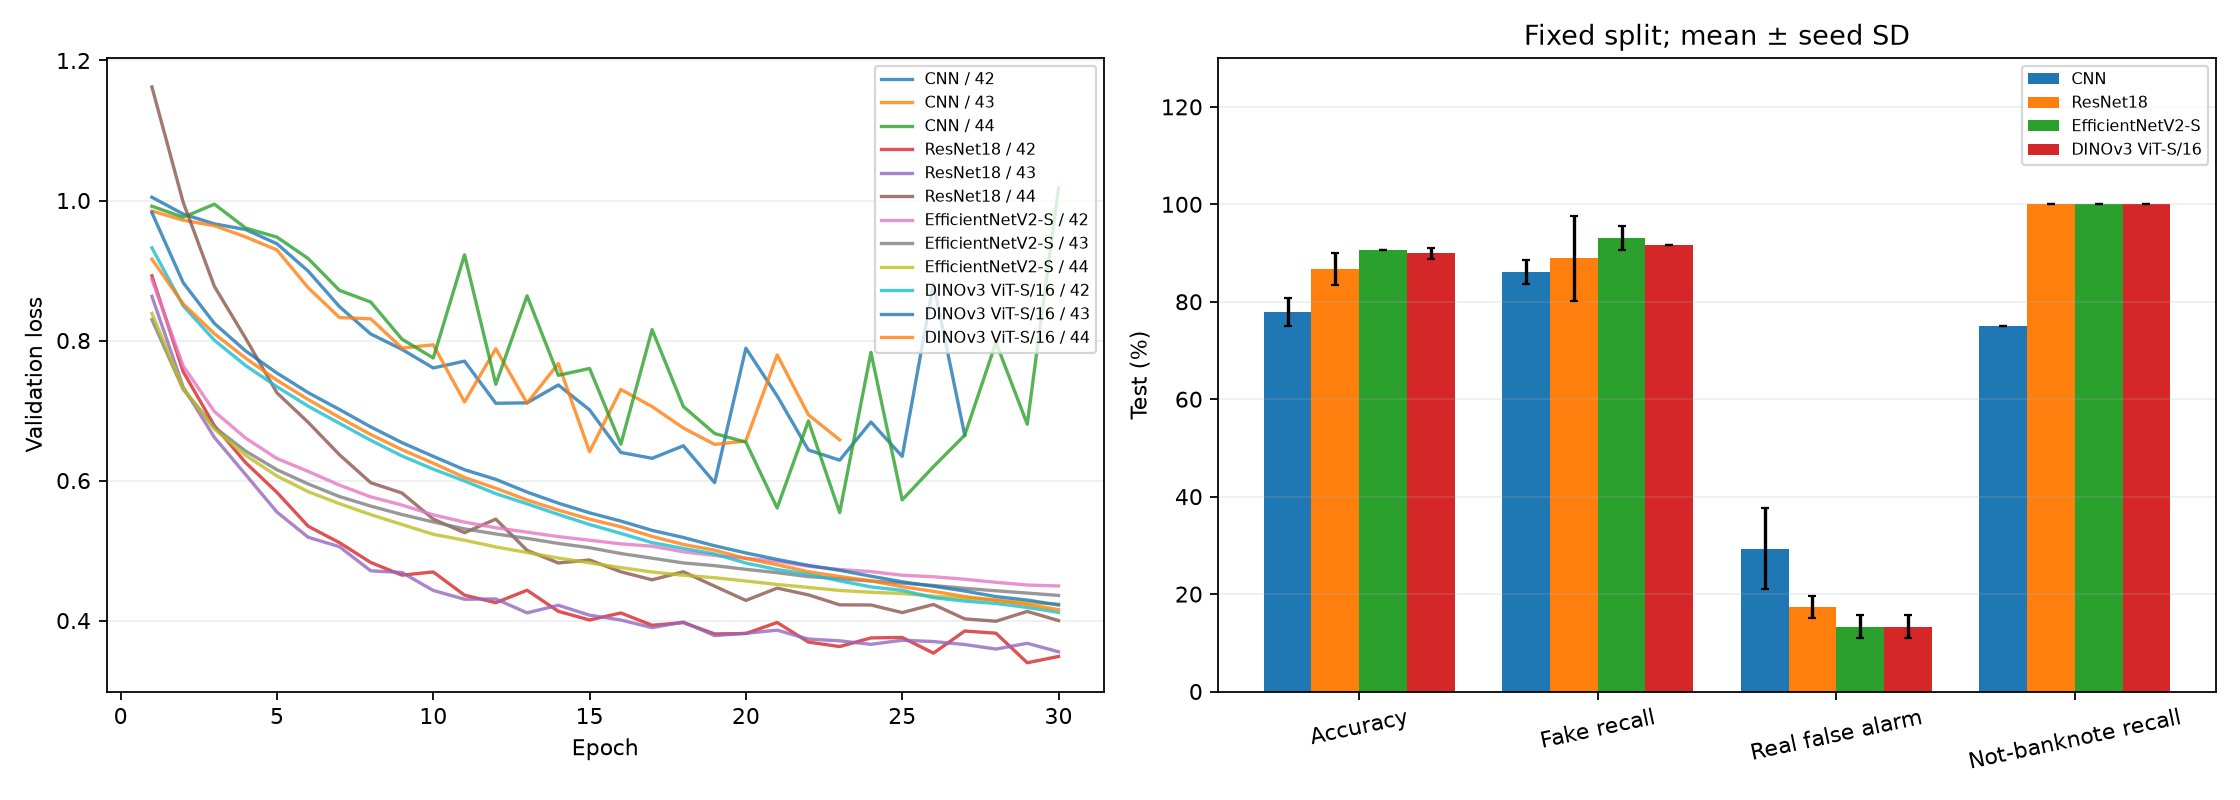

Figure: /Users/grz/Documents/dataai/CSC_51073_EP/project/Fake_Money_Detection/runs/course_models_archive_v3/confusion_matrices.png


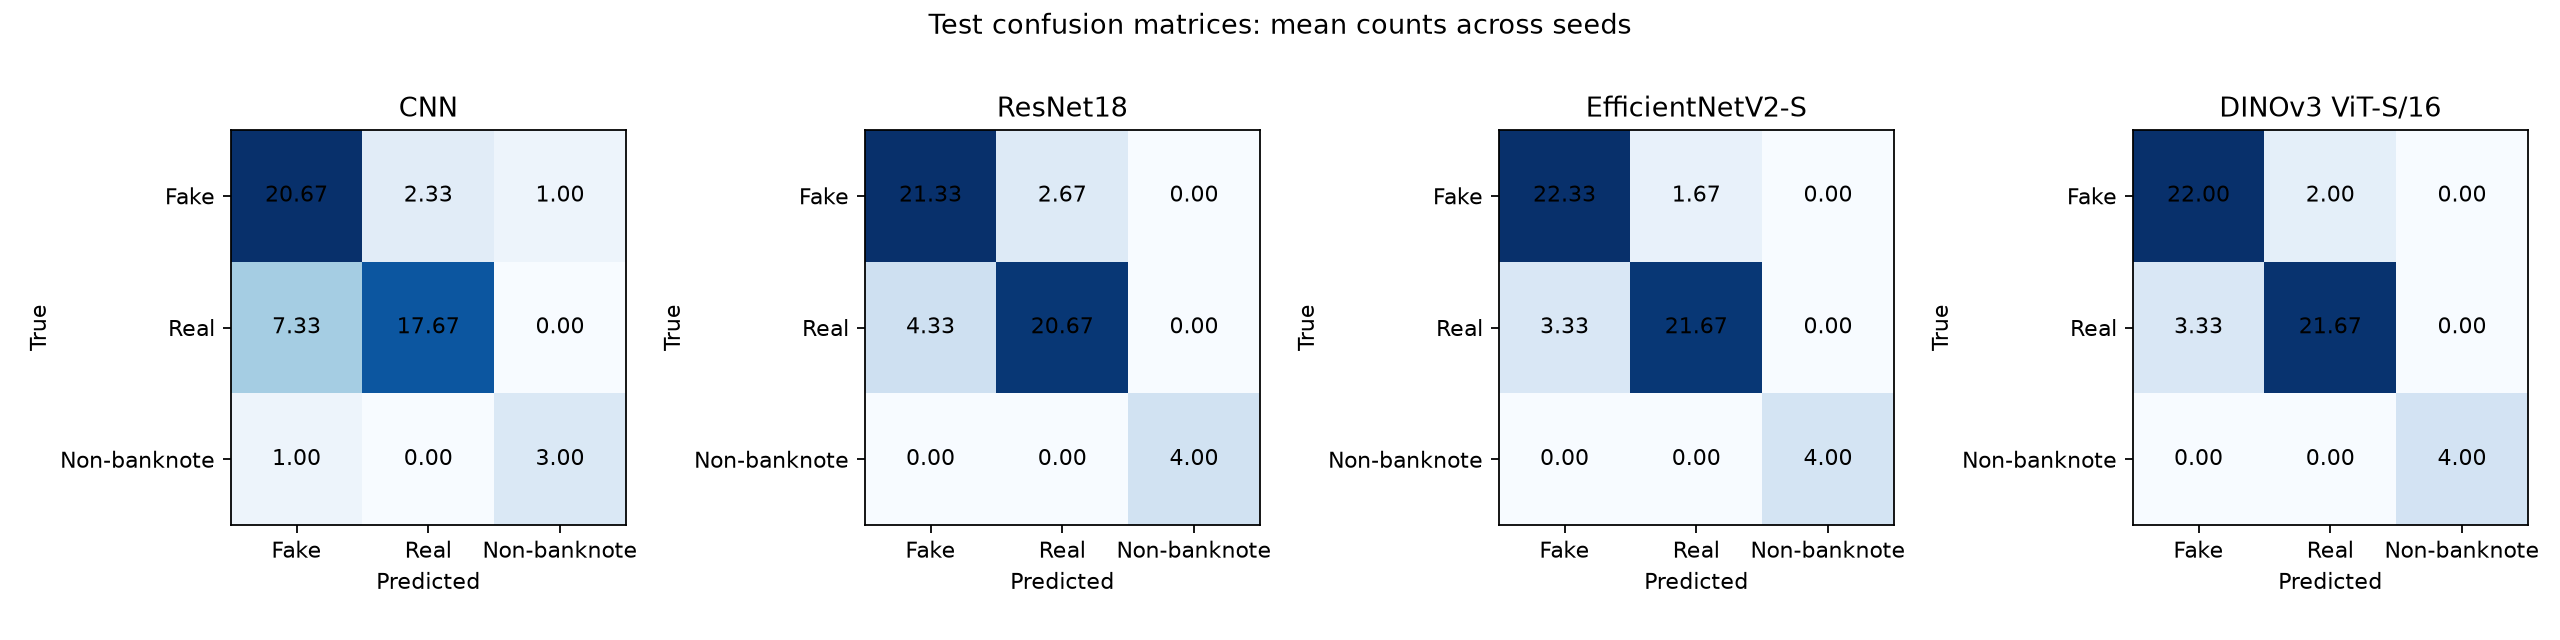

In [4]:
results_file = COMPARISON / "comparison.json"
results = json.loads(results_file.read_text()) if results_file.exists() else None
if results:
    assert results["protocol"]["manifest_sha256"] == hashlib.sha256((DATA / "manifest.json").read_bytes()).hexdigest()
    archs = results["protocol"]["models"]
    metrics = {"accuracy":"Accuracy", "fake_recall":"Fake recall", "fake_fnr":"Missed fakes",
               "real_false_alarm_rate":"Real flagged fake", "fake_precision":"Fake precision"}
    table = {}
    for model in archs:
        stats = results["summary"]["test"][model]
        row = {title: f"{100*stats[k]['mean']:.1f} ± {100*stats[k]['sd']:.1f}%" for k, title in metrics.items()}
        row["Seconds per fit"] = round(np.mean([r["training_seconds"] for r in results["runs"]
                                                if r["architecture"] == model]), 1)
        table[MODEL_NAMES[model]] = row
    display(pd.DataFrame.from_dict(table, orient="index"))
    for name in ("comparison.png", "confusion_matrices.png"):
        print("Figure:", (COMPARISON / name).resolve())
        with Image.open(COMPARISON / name) as figure:
            display(figure.copy())
else:
    print("Run the training appendix to generate the comparison, then replay Sections 2 and 3.")

### Check two photographs where the models disagree

On the expanded test set EfficientNetV2-S gained **4.17 percentage points in fake recall** over ResNet18 and lowered the real-note false-alarm rate by **4.00 points**. Against DINOv3 its recall gain was **1.39 points** and both flagged **13.33%** of real notes.

**Can two models have the same accuracy while missing different notes?** Use seed 42, where both EfficientNet and DINOv3 got 48 of 53 right. The first panel shows the first fake-labelled note in roster order that EfficientNet caught and DINOv3 missed. The second shows the reverse. Read the printed paths to find each input and its source. The table below also shows the CNN and ResNet18 predictions for the first six errors across the four models.

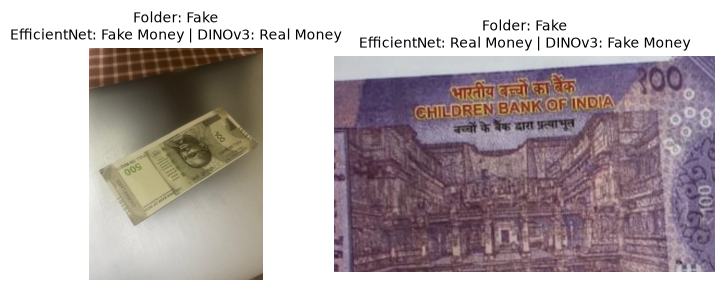

,source_path,Model input file
split_path,,
test/fake money/500_12ede66445aa3822.jpg,archive/data/data/fake/500/IMG-20250717-WA0231.jpg,dataset_archive_course_v3/test/fake money/500_12ede66445aa3822.jpg
test/fake money/100_4b6f91bfcd036823.png,archive/data/data/fake/100/Screenshot 2025-04-05 at 11.24.48ÔÇ»AM.png,dataset_archive_course_v3/test/fake money/100_4b6f91bfcd036823.png


,source_path,Model input file,Folder label,CNN,ResNet18,EfficientNetV2-S,DINOv3 ViT-S/16
split_path,,,,,,,
test/fake money/100_4b6f91bfcd036823.png,archive/data/data/fake/100/Screenshot 2025-04-05 at 11.24.48ÔÇ»AM.png,dataset_archive_course_v3/test/fake money/100_4b6f91bfcd036823.png,Fake Money,Fake Money,Fake Money,Real Money,Fake Money
test/fake money/500_92c7017763de5a1b.jpg,archive/data/data/fake/500/IMG-20250717-WA0144.jpg,dataset_archive_course_v3/test/fake money/500_92c7017763de5a1b.jpg,Fake Money,Real Money,Real Money,Fake Money,Fake Money
test/fake money/500_12ede66445aa3822.jpg,archive/data/data/fake/500/IMG-20250717-WA0231.jpg,dataset_archive_course_v3/test/fake money/500_12ede66445aa3822.jpg,Fake Money,Real Money,Fake Money,Fake Money,Real Money
test/fake money/500_c8ec7e37f9739637.jpg,archive/data/data/fake/500/IMG-20250717-WA0142.jpg,dataset_archive_course_v3/test/fake money/500_c8ec7e37f9739637.jpg,Fake Money,Fake Money,Fake Money,Fake Money,Real Money
test/fake money/2000_6ed5ae16eb6d0ce8.png,archive/data/data/fake/2000/Screenshot 2025-10-12 105738.png,dataset_archive_course_v3/test/fake money/2000_6ed5ae16eb6d0ce8.png,Fake Money,Not a Banknote,Fake Money,Fake Money,Fake Money
test/OR money/100_f5a765f1ce4bb123.jpg,archive/data/data/real/100/IMG20221010134034.jpg,dataset_archive_course_v3/test/OR money/100_f5a765f1ce4bb123.jpg,Real Money,Fake Money,Real Money,Real Money,Real Money


In [5]:
if results:
    cases = paths[paths["split"] == "test"].set_index("split_path").copy()
    for run in results["runs"]:
        if run["seed"] == 42:
            cases[MODEL_NAMES[run["architecture"]]] = {
                Path(*Path(p["path"]).parts[-3:]).as_posix(): names[p["predicted_label"]]
                for p in run["test_predictions"]}
    model_cols = [MODEL_NAMES[m] for m in archs]
    assert cases[model_cols].notna().all().all()
    fake = cases[cases["label"] == "fake money"]
    efficient = fake["EfficientNetV2-S"] == "Fake Money"
    dino = fake["DINOv3 ViT-S/16"] == "Fake Money"
    pair = pd.concat([fake[efficient & ~dino].head(1), fake[dino & ~efficient].head(1)])
    if not pair.empty:
        captions = ["Folder: Fake\nEfficientNet: " + e + " | DINOv3: " + d
                    for e, d in zip(pair["EfficientNetV2-S"], pair["DINOv3 ViT-S/16"])]
        show_photos(pair["Model input file"], captions)
    missed = cases[model_cols].ne(cases["Folder label"], axis=0).any(axis=1)
    with pd.option_context("display.max_colwidth", None):
        display(pair[["source_path", "Model input file"]])
        display(cases.loc[missed, ["source_path", "Model input file", "Folder label", *model_cols]].head(6))

## 3. Why did the model ranking change?

The original four-model comparison used **65 train / 12 validation / 12 test**. Each test class contained four images. One more correct prediction changed single-seed accuracy by **8.33 percentage points**. The expanded comparison used **187 / 38 / 53**, with **44 of 53 test images** from the 500- and 2000-rupee folders. Four non-banknote test photos occur in both sets. The 18-image pilot used in the CAM lab is a third, separate experiment.

Read the table from left to right. The first two columns score different fits on the same old test set. The last two columns score **the very same expanded-data checkpoints** on different test sets. Every entry averages seeds 42, 43 and 44. [Original completed-run log](runs/course_models_archive_v3/rank_check/original_four_model_run.log) · [Checkpoint hashes and paired predictions](runs/course_models_archive_v3/rank_check/fixed_checkpoint_test.json)

In [6]:
rank_dir = COMPARISON / "rank_check"
if results and (rank_dir / "fixed_checkpoint_test.json").exists():
    rank = json.loads((rank_dir / "fixed_checkpoint_test.json").read_text())
    assert hashlib.sha256((rank_dir / "original_four_model_run.log").read_bytes()).hexdigest() == rank["historical_log_sha256"]
    assert all(hashlib.sha256((Path(folder) / "manifest.json").read_bytes()).hexdigest() == digest
               for folder, digest in rank["manifests"].items())
    assert {(r["architecture"], r["seed"], r["checkpoint_sha256"]) for r in results["runs"]} == {
        (r["model"], r["seed"], r["checkpoint_hash"]) for r in rank["runs"]}
    accuracy = pd.DataFrame({
        "Original fit → old test": {m: rank["historical"][m]["accuracy"]["mean"] for m in archs},
        "Expanded fit → old test": {m: rank["fixed_checkpoint_means"][m]["old"]["accuracy"] for m in archs},
        "Expanded fit → new test": {m: rank["fixed_checkpoint_means"][m]["new"]["accuracy"] for m in archs}})
    display((100 * accuracy.rename(index=MODEL_NAMES)).round(2).rename_axis("Accuracy (%)"))

,Original fit → old test,Expanded fit → old test,Expanded fit → new test
Accuracy (%),,,
CNN,55.56,77.78,77.99
ResNet18,83.33,63.89,86.79
EfficientNetV2-S,80.56,66.67,90.57
DINOv3 ViT-S/16,88.89,61.11,89.94


**Read across one row first.** DINOv3 scored 88.89% in the original run. After fitting on the expanded data it scored 61.11% on those same 12 photographs. With those expanded weights held fixed, it scored 89.94% on the new 53. Changing the fit had already reversed the order of EfficientNet and DINOv3 on the old images. Training photographs, validation images and device (CPU to MPS) changed together.

**Now count the difference in photographs.** Across the three seeds, EfficientNet and DINOv3 got 48 vs 48, 48 vs 47 and 48 vs 48 correct. Over those repeated predictions EfficientNet gained two correct decisions on 500-rupee images and two on 2000-rupee images, and lost three on 100-rupee images. That leaves **one additional correct decision**. There were only two 100-rupee photographs. Compared with ResNet18, the corresponding differences were +6, +2 and −2.

**What would you report?** EfficientNet led on expanded-test accuracy and fake recall. DINOv3 was close. ResNet18 led on mean validation accuracy (83.33%). The old-test overlap check found no exact, known-group or near-hash match to expanded training or validation. The photographed notes lack verified physical IDs. **Lab 2** uses the earlier, fixed ResNet18 checkpoint so that its CAM measurements can be reproduced.

## Appendix · Reproduce the training or revisit the CAM checkpoint

The main results are complete above. The cells below keep the full PyTorch implementation in this notebook. In a fresh kernel run the setup at the top first. The last cell resumes missing comparison runs with the saved protocol and reads the saved metrics when all runs are complete. Set `RUN_DEMOS` below to enable the three-epoch CNN exercise and the original 18-image CAM pilot evaluation.

In [7]:
RUN_DEMOS = False

### A. Load images and preserve the complete frame

In [8]:
def set_seed(seed):
    """Seed the Python, NumPy and PyTorch random generators for repeatable training runs."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def get_device():
    """Choose the first available device in the order CUDA, Apple MPS, then CPU."""
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

In [9]:
def list_images(folder):
    """Return sorted image paths from one class folder so each run visits the same files."""
    # The pilot training manifest includes an AVIF photograph.
    extensions = {".jpg", ".jpeg", ".png", ".avif"}
    return [str(p) for p in sorted(Path(folder).iterdir())
            if p.is_file() and p.suffix.lower() in extensions]


# The manifest fixes the class order for all splits. Older datasets use the binary order.
def dataset_class_names(data_dir):
    """Read class names in label-index order, using the legacy binary mapping for datasets
    without a manifest.
    """
    manifest = Path(data_dir) / "manifest.json"
    if not manifest.is_file():
        return list(CLASS_NAMES)
    mapping = json.loads(manifest.read_text())["class_to_idx"]
    ordered = sorted(mapping, key=mapping.get)
    if mapping != {name: i for i, name in enumerate(ordered)} or ordered not in [CLASS_NAMES, THREE_CLASS_NAMES]:
        raise ValueError("Expected consecutive fake/real or fake/real/not-a-banknote class indices")
    return ordered


# Folder names follow the dataset convention: "OR money" is the real-banknote class.
class MoneyDataset(Dataset):
    """Load banknote photographs and their folder labels from one dataset split."""
    def __init__(self, root, train=False, transform=None, class_names=None):
        """Index each file by its class and store the transform applied when an image is
        requested.
        """
        self.samples = []
        self.transform = transform or TestTransform()
        self.class_names = class_names or dataset_class_names(Path(root).parent)
        for label, name in enumerate(self.class_names):
            folder = Path(root) / name
            if not folder.is_dir():
                raise FileNotFoundError(f"Class directory not found: {folder}")
            images = list_images(folder)
            if not images:
                raise ValueError(f"No images in class directory: {folder}")
            self.samples.extend((p, label) for p in images)

    def __len__(self):
        """Return the number of indexed photographs in this split."""
        return len(self.samples)

    def __getitem__(self, index):
        """Open one image as RGB and return its transformed tensor and integer class label."""
        path, label = self.samples[index]
        with Image.open(path) as image:
            image = image.convert("RGB")
        return self.transform(image), label

In [10]:
MODEL_CONFIG = {
    "cnn": {"img_size": 64, "preprocessing": "RGB_resize_bilinear_scale_0_1"},
    "resnet18": {"img_size": 224, "preprocessing": "ResNet18_IMAGENET1K_V1_transforms"},
    "efficientnet_v2_s": {"img_size": 224, "preprocessing": "EfficientNetV2S_RGB_letterbox_224_ImageNetNorm"},
    "dinov3_vits16": {"img_size": 224, "preprocessing": "DINOv3ViTS16_RGB_letterbox_224_ImageNetNorm"},
}


LETTERBOX_CONFIG = {
    "cnn": {"img_size": 64, "preprocessing": "RGB_letterbox_64_scale_0_1"},
    "resnet18": {"img_size": 224, "preprocessing": "ResNet18_RGB_letterbox_224_ImageNetNorm"},
    "efficientnet_v2_s": MODEL_CONFIG["efficientnet_v2_s"],
    "dinov3_vits16": MODEL_CONFIG["dinov3_vits16"],
}


def supported_resize_modes(architecture):
    """List the resize modes supported by the selected architecture and its checkpoints."""
    return ("legacy", "letterbox") if architecture in ("cnn", "resnet18") else ("letterbox",)


def preprocessing_config(architecture, resize_mode):
    """Return the expected input size and preprocessing name for a model and resize mode."""
    if architecture not in MODEL_CONFIG or resize_mode not in supported_resize_modes(architecture):
        raise ValueError(f"Unsupported preprocessing: {architecture}/{resize_mode}; new models require letterbox")
    return dict((LETTERBOX_CONFIG if resize_mode == "letterbox" else MODEL_CONFIG)[architecture])


def transform_for_model(model):
    """Use the preprocessing that produced this checkpoint, never override it silently."""
    return TestTransform(model.architecture, getattr(model, "resize_mode", None))

In [11]:
def letterbox_geometry(original_size, target_size):
    """Fit the complete frame into a square, preserving its aspect ratio."""
    width, height = original_size
    scale = min(target_size / width, target_size / height)
    new_width = max(1, min(target_size, round(width * scale)))
    new_height = max(1, min(target_size, round(height * scale)))
    left, top = (target_size - new_width) // 2, (target_size - new_height) // 2
    return {
        "resize_mode": "letterbox", "original_size_wh": [width, height],
        "resized_size_wh": [new_width, new_height],
        "content_box_xyxy": [left, top, left + new_width, top + new_height],
        "scale_xy": [new_width / width, new_height / height],
        "output_size_wh": [target_size, target_size],
    }


class TestTransform:
    """Prepare a photograph using the input geometry and normalization expected by the
    classifier.
    """
    def __init__(self, architecture="cnn", resize_mode=None):
        """Select the input size and resize procedure for this architecture and checkpoint
        format.
        """
        # Keep the direct-call default compatible with historical checkpoints.
        # New training explicitly requests letterbox; inference reads checkpoint metadata.
        resize_mode = resize_mode or ("legacy" if architecture in ("cnn", "resnet18") else "letterbox")
        if architecture not in MODEL_CONFIG or resize_mode not in supported_resize_modes(architecture):
            raise ValueError(f"Unsupported preprocessing: {architecture}/{resize_mode}")
        self.architecture = architecture
        self.resize_mode = resize_mode
        self.size = preprocessing_config(architecture, resize_mode)["img_size"]
        self.preprocess = None
        if architecture == "resnet18" and resize_mode == "legacy":
            self.preprocess = ResNet18_Weights.IMAGENET1K_V1.transforms()

    def geometry(self, image):
        """Describe the resize operation and, for letterboxing, the location of the photo inside
        the square.
        """
        if self.resize_mode == "letterbox":
            return letterbox_geometry(image.size, self.size)
        return {"resize_mode": "legacy", "original_size_wh": list(image.size),
                "output_size_wh": [self.size, self.size],
                "operation": "resize_short_256_center_crop_224" if self.architecture == "resnet18" else "stretch_resize"}

    def __call__(self, image):
        """Convert one photograph to a channel-first tensor using the selected preprocessing."""
        image = image.convert("RGB")
        if self.preprocess is not None:
            return self.preprocess(image)
        if self.resize_mode == "legacy":
            image = image.resize((self.size, self.size), Image.Resampling.BILINEAR)
            return torch.from_numpy(np.array(image, dtype=np.float32) / 255.0).permute(2, 0, 1)
        # Resize the full photograph before padding so details at the edges stay in view.
        geometry = self.geometry(image)
        image = image.resize(tuple(geometry["resized_size_wh"]), Image.Resampling.BILINEAR)
        tensor = torch.from_numpy(np.array(image, dtype=np.float32) / 255.0).permute(2, 0, 1)
        if self.architecture in TRANSFER_MODELS:
            mean = tensor.new_tensor([.485, .456, .406])[:, None, None]
            std = tensor.new_tensor([.229, .224, .225])[:, None, None]
            tensor = (tensor - mean) / std
        # Normalized zero is ImageNet mean RGB for transfer models; black for CNN.
        canvas = torch.zeros(3, self.size, self.size, dtype=tensor.dtype)
        left, top, right, bottom = geometry["content_box_xyxy"]
        canvas[:, top:bottom, left:right] = tensor
        return canvas


# Vary brightness and contrast during training to simulate changes in lighting.
class TrainAug:
    """Apply random lighting changes to training images before the classifier's usual
    preprocessing.
    """
    def __init__(self, architecture="cnn", resize_mode=None):
        """Set up the resize and normalization that follow the lighting augmentation."""
        self.transform = TestTransform(architecture, resize_mode)

    def __call__(self, image):
        """Randomly adjust brightness and contrast, then return the transformed training tensor."""
        image = ImageEnhance.Brightness(image).enhance(random.uniform(0.9, 1.1))
        image = ImageEnhance.Contrast(image).enhance(random.uniform(0.9, 1.1))
        return self.transform(image)

In [12]:
def sha256(path):
    """Hash a file's bytes to identify the exact dataset manifest or checkpoint used in a run."""
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def save_json(path, value):
    """Write JSON to a temporary file and replace the destination once the write completes."""
    # Atomic progress files allow safe continuation after an interrupted process.
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False) + "\n")
    temporary.replace(path)


def verify_split(data_dir):
    """Audit manifest/files without decoding test pixels or computing test predictions."""
    manifest = json.loads((data_dir / "manifest.json").read_text())
    if manifest["class_to_idx"] != {name: i for i, name in enumerate(dataset_class_names(data_dir))}:
        raise ValueError("Manifest class mapping mismatch")
    hashes, groups, expected = {}, {}, set()
    for row in manifest["samples"]:
        path = data_dir / row["destination"]
        if path.resolve() in expected:
            raise ValueError(f"Repeated manifest destination: {path}")
        expected.add(path.resolve())
        if sha256(path) != row["sha256"]:
            raise ValueError(f"File hash mismatch: {path}")
        # Keep exact pixel duplicates and related images with the same group ID in a single split.
        for table, key in ((hashes, row["pixel_hash"]), (groups, row["group_id"])):
            if key in table and table[key] != row["split"]:
                raise ValueError("Duplicate/perceptual group leaks across splits")
            table[key] = row["split"]
    actual = {Path(p).resolve() for split in ("train", "val", "test")
              for p, _ in MoneyDataset(data_dir / split).samples}
    if actual != expected:
        raise ValueError("Dataset directories differ from manifest")
    return sha256(data_dir / "manifest.json")

### B. Build, train and evaluate the classifiers

In [13]:
class FakeMoneyCNN(nn.Module):
    """Classify 64-by-64 RGB photographs using three convolution and pooling blocks."""
    def __init__(self, num_classes=2):
        """Build the feature layers and a head with one binary logit or one logit per class."""
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        # Three pooling steps reduce each 64 x 64 input to 32 feature maps of size 8 x 8.
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(32 * 8 * 8, 128), nn.ReLU(),
            nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 1 if num_classes == 2 else num_classes),
        )

    def forward(self, x):
        """Pass a batch of images through the feature layers and return raw class scores."""
        return self.classifier(self.features(x))

In [14]:
# For binary checkpoints the single logit represents Real. Column zero always represents Fake.
def probability_tensor(logits):
    """Convert model logits to class probabilities with Fake at index 0 and Real at index 1."""
    if logits.shape[1] == 1:
        p_real = logits[:, 0].sigmoid()
        return torch.stack([1 - p_real, p_real], dim=1)
    return logits.softmax(dim=1)


def classification_loss(logits, labels, reduction="mean"):
    """Use binary cross-entropy for a single Real logit and multiclass cross-entropy for class
    logits.
    """
    if logits.shape[1] == 1:
        return nn.functional.binary_cross_entropy_with_logits(logits[:, 0], labels.float(), reduction=reduction)
    return nn.functional.cross_entropy(logits, labels.long(), reduction=reduction)


def classification_metrics(labels, p_real, fake_threshold=FAKE_THRESHOLD):
    """Binary input: p(real) or Nx2 probabilities; three-class input: Nx3 probabilities.
    Confusion matrix rows are true classes and columns are predicted classes.

    Binary predictions use the fake threshold; three-class predictions use argmax.
    A fake classified as not-a-banknote also counts as a false negative.
    """
    labels = np.asarray(labels, dtype=np.int64)
    probs = np.asarray(p_real, dtype=np.float64)
    if probs.ndim == 1:
        probs = np.column_stack([1 - probs, probs])
    if probs.ndim != 2 or probs.shape[1] not in (2, 3) or len(labels) != len(probs) or not len(labels):
        raise ValueError("Expected nonempty Nx2/Nx3 probabilities or binary p(real), matching the labels")
    if not 0 <= fake_threshold <= 1 or not np.isfinite(probs).all():
        raise ValueError("Invalid threshold or nonfinite probabilities")
    nclasses = probs.shape[1]
    if np.any(labels < 0) or np.any(labels >= nclasses):
        raise ValueError("Label outside the supported class range")
    preds = np.where(probs[:, 0] >= fake_threshold, 0, 1) if nclasses == 2 else probs.argmax(axis=1)
    cm = np.zeros((nclasses, nclasses), dtype=np.int64)
    np.add.at(cm, (labels, preds), 1)
    def ratio(a, b):
        """Return a rate, or None when its denominator is zero and the rate is undefined."""
        return float(a / b) if b else None
    # Each row total counts examples of one true class. The real false-alarm rate uses the Real row.
    recalls = [ratio(cm[i, i], cm[i].sum()) for i in range(nclasses)]
    metrics = {
        "n": len(labels), "accuracy": float(np.trace(cm) / len(labels)),
        "fake_recall": recalls[0], "fake_fnr": ratio(cm[0].sum() - cm[0, 0], cm[0].sum()),
        "fake_precision": ratio(cm[0, 0], cm[:, 0].sum()),
        "real_false_alarm_rate": ratio(cm[1, 0], cm[1].sum()),
        "real_recall": recalls[1],
        "balanced_accuracy": float(np.mean([v for v in recalls if v is not None])),
        "confusion_matrix": cm.tolist(),
    }
    if nclasses == 3:
        metrics.update({"not_banknote_recall": recalls[2],
                        "not_banknote_as_fake_rate": ratio(cm[2, 0], cm[2].sum()),
                        "fake_as_real_rate": ratio(cm[0, 1], cm[0].sum()),
                        "fake_as_not_banknote_rate": ratio(cm[0, 2], cm[0].sum())})
    return metrics


def evaluate(model, loader, device, fake_threshold=FAKE_THRESHOLD, *, return_predictions=False):
    """Score a loader in evaluation mode and return its mean loss and classification metrics.

    With return_predictions=True, also return the labels and class probabilities in loader
    order.
    """
    model.eval()
    labels_all, probs_all = [], []
    loss_sum = 0.0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            logits = model(images)
            # Sum individual losses before dividing by sample count so a short final batch has the correct weight.
            loss_sum += classification_loss(logits, labels, reduction="sum").item()
            labels_all.extend(labels.cpu().tolist())
            probs_all.extend(probability_tensor(logits).cpu().tolist())
    metrics = classification_metrics(labels_all, probs_all, fake_threshold)
    metrics["loss"] = loss_sum / metrics["n"]
    if return_predictions:
        return metrics, labels_all, probs_all
    return metrics

In [15]:
# The CNN learns all its weights. Each transfer model learns a new head on frozen features.
def build_model(architecture="cnn", pretrained=False, class_names=None):
    """Build the requested classifier with a head sized for the dataset's classes.

    For transfer models, optionally load pretrained weights and freeze the backbone for head
    training.
    """
    class_names = list(class_names or CLASS_NAMES)
    num_classes = len(class_names)
    # Binary checkpoints store one Real logit. Three-class checkpoints store one per class.
    outputs = 1 if num_classes == 2 else num_classes
    if architecture == "cnn":
        model = FakeMoneyCNN(num_classes)
    elif architecture == "resnet18":
        weights = ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        model = resnet18(weights=weights)
        model.requires_grad_(False)
        model.fc = nn.Linear(model.fc.in_features, outputs)
    elif architecture == "efficientnet_v2_s":
        weights = EfficientNet_V2_S_Weights.IMAGENET1K_V1 if pretrained else None
        model = efficientnet_v2_s(weights=weights)
        model.requires_grad_(False)
        model.classifier[-1] = nn.Linear(model.classifier[-1].in_features,
                                         outputs)
    elif architecture == "dinov3_vits16":
        if timm is None:
            raise RuntimeError("DINOv3 requires timm. Install requirements-models.txt.")
        # Public timm conversion of Meta DINOv3 weights; no remote Python code.
        # 224 is divisible by patch size 16 and matches the other transfer models.
        model = timm.create_model(DINO_TIMM_MODEL, pretrained=pretrained, img_size=224, num_classes=0)
        model.requires_grad_(False)
        model.head = nn.Linear(model.num_features, outputs)
    else:
        raise ValueError(f"Unknown architecture: {architecture}")
    model.architecture = architecture
    model.class_names = class_names
    return model


def classification_head(model):
    """Return the trainable head's attribute name on a transfer model, or None for the custom
    CNN.
    """
    return {"resnet18": "fc", "efficientnet_v2_s": "classifier", "dinov3_vits16": "head"}.get(model.architecture)


def initialization_metadata(architecture):
    """Describe this architecture's training initialization for the experiment record."""
    if architecture == "dinov3_vits16":
        if timm is None:
            raise RuntimeError("DINOv3 requires timm. Install requirements-models.txt.")
        return {"initial_weights": "DINOv3_LVD1689M_timm", "model_variant": DINO_TIMM_MODEL,
                "timm_version": str(timm.__version__)}
    return {"initial_weights": "IMAGENET1K_V1" if architecture in TRANSFER_MODELS else "random",
            "model_variant": architecture}

In [16]:
def load_checkpoint(path, device=None):
    """Restore the trained network and its class order, decision threshold and preprocessing.

    Return the model in evaluation mode together with the saved checkpoint metadata.
    """
    device = torch.device(device) if device is not None else get_device()
    checkpoint = torch.load(path, map_location=device, weights_only=True)
    architecture = checkpoint.get("architecture", "FakeMoneyCNN")
    architecture = "cnn" if architecture == "FakeMoneyCNN" else architecture
    config = MODEL_CONFIG.get(architecture)
    mapping = checkpoint.get("class_to_idx", {})
    class_names = sorted(mapping, key=mapping.get)
    if config is None or class_names not in [CLASS_NAMES, THREE_CLASS_NAMES] or mapping != {name: i for i, name in enumerate(class_names)}:
        raise ValueError("Checkpoint architecture or class mapping does not match")
    # Older checkpoints record the transform name and input size without an explicit resize mode.
    matched_modes = [mode for mode in supported_resize_modes(architecture)
                     if all(checkpoint.get(key) == value for key, value in preprocessing_config(architecture, mode).items())]
    if len(matched_modes) != 1:
        raise ValueError("Checkpoint input size or preprocessing does not match a supported configuration")
    resize_mode = matched_modes[0]
    if checkpoint.get("resize_mode", resize_mode) != resize_mode:
        raise ValueError("Conflicting resize-mode and preprocessing metadata")
    # The checkpoint contains the backbone; loading never downloads pretrained weights.
    model = build_model(architecture, pretrained=False, class_names=class_names).to(device)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()
    model.fake_threshold = checkpoint["fake_threshold"]
    model.resize_mode = resize_mode
    model.preprocessing = checkpoint["preprocessing"]
    return model, checkpoint

In [17]:
def evaluate_split(model, dataset, device, batch_size):
    """Return split-level metrics and a prediction record for each file in dataset order."""
    # Preserve dataset order so each prediction can be matched to its image path.
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)
    metrics, labels, probabilities = evaluate(
        model, loader, device, model.fake_threshold, return_predictions=True
    )
    rows = []
    for (path, _), label, probs in zip(dataset.samples, labels, probabilities):
        if len(probs) == 2:
            predicted = 0 if probs[0] >= model.fake_threshold else 1
        else:
            predicted = int(np.argmax(probs))
        rows.append({"path": path, "true_label": label, "predicted_label": predicted,
                     "probabilities": probs, "p_fake": probs[0], "p_real": probs[1]})
    return metrics, rows

In [18]:
def default_training_dir(class_names, architecture, resize_mode):
    """Build the default run directory name from the class count, architecture and resize mode."""
    prefix = "threeclass" if len(class_names) == 3 else "clean"
    return Path.cwd() / "runs" / f"{prefix}_{architecture}_{resize_mode}"


def train(epochs=EPOCHS, data_dir=DATA, output_dir=None,
          patience=8, device=None, seed=SEED, architecture="cnn", resize_mode="letterbox",
          batch_size=BATCH_SIZE):
    """Train one model on the training split and select its checkpoint by validation loss.

    Save the best weights and epoch history, then return the selected model and its training
    history.
    """
    if epochs < 1 or patience < 1 or batch_size < 1:
        raise ValueError("epochs, patience and batch_size must be positive")
    if architecture not in MODEL_CONFIG:
        raise ValueError(f"Unknown architecture: {architecture}")
    set_seed(seed)
    device = torch.device(device) if device is not None else get_device()
    config = preprocessing_config(architecture, resize_mode)
    data_dir = Path(data_dir)
    class_names = dataset_class_names(data_dir)
    output_dir = Path(output_dir) if output_dir else default_training_dir(class_names, architecture, resize_mode)
    class_to_idx = {name: i for i, name in enumerate(class_names)}
    # Training never constructs a test dataset and never resumes old weights.
    train_ds = MoneyDataset(data_dir / "train", transform=TrainAug(architecture, resize_mode), class_names=class_names)
    val_ds = MoneyDataset(data_dir / "val", transform=TestTransform(architecture, resize_mode), class_names=class_names)
    # A separate generator gives every architecture the same shuffle order for a given seed.
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                              generator=torch.Generator().manual_seed(seed))
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)
    output_dir.mkdir(parents=True, exist_ok=True)
    print(f"architecture={architecture}; seed={seed}; device={device}; resize_mode={resize_mode}; train={len(train_ds)}, val={len(val_ds)}; test not loaded")
    model = build_model(architecture, pretrained=(architecture in TRANSFER_MODELS), class_names=class_names).to(device)
    optimizer = torch.optim.Adam((p for p in model.parameters() if p.requires_grad), lr=LR)
    started = time.perf_counter()
    history = {"loss": [], "acc": [], "val_acc": [], "epochs": []}
    best_loss, stale = float("inf"), 0
    for epoch in range(1, epochs + 1):
        if architecture in TRANSFER_MODELS:
            # Freeze BatchNorm, stochastic depth and backbone dropout during head training.
            model.eval()
            getattr(model, classification_head(model)).train()
        else:
            model.train()
        running, correct, total = 0.0, 0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = classification_loss(logits, labels)
            loss.backward()
            optimizer.step()
            running += loss.item() * len(labels)
            probs = probability_tensor(logits)
            preds = torch.where(probs[:, 0] >= FAKE_THRESHOLD, 0, 1) if len(class_names) == 2 else probs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += len(labels)
        val = evaluate(model, val_loader, device)
        record = {"epoch": epoch, "train_loss": running / total,
                  "train_accuracy": correct / total, "val": val}
        history["loss"].append(running / total)
        history["acc"].append(correct / total)
        history["val_acc"].append(val["accuracy"])
        history["epochs"].append(record)
        print(f"epoch {epoch}/{epochs}: train_loss={running/total:.4f} "
              f"val_loss={val['loss']:.4f} val_acc={val['accuracy']:.3f} "
              f"fake_recall={val['fake_recall']:.3f} "
              f"real_false_alarm={val['real_false_alarm_rate']:.3f}")
        # Validation loss selects the checkpoint and resets the early-stopping counter.
        if val["loss"] < best_loss:
            best_loss, stale = val["loss"], 0
            torch.save({
                "model_state_dict": model.state_dict(), "architecture": architecture,
                "class_to_idx": class_to_idx, **config, "resize_mode": resize_mode,
                "decision_rule": "argmax" if len(class_names) == 3 else "fake_threshold",
                **initialization_metadata(architecture),
                "training_mode": "frozen_backbone_head_only" if architecture in TRANSFER_MODELS else "all_parameters",
                "batch_size": batch_size, "learning_rate": LR,
                "fake_threshold": FAKE_THRESHOLD, "epoch": epoch, "seed": seed,
                "selection_metric": "val_loss", "val_metrics": val,
                "data_dir": str(data_dir.resolve()),
            }, output_dir / "best.pt")
        else:
            stale += 1
        (output_dir / "history.json").write_text(json.dumps(history, indent=2))
        if stale >= patience:
            print(f"Early stopping: validation loss did not improve for {patience} consecutive epochs")
            break
    history["training_seconds"] = time.perf_counter() - started
    history["architecture"] = architecture
    history["seed"] = seed
    history["device"] = str(device)
    history["resize_mode"] = resize_mode
    history["preprocessing"] = config["preprocessing"]
    history["batch_size"] = batch_size
    (output_dir / "history.json").write_text(json.dumps(history, indent=2))
    # Return the validation-selected weights even when early stopping ends on a later epoch.
    model, checkpoint = load_checkpoint(output_dir / "best.pt", device)
    print(f"Best checkpoint: epoch={checkpoint['epoch']}; {output_dir / 'best.pt'}")
    return model, history

### C. Save checkpoints, compare seeds and produce the figures

In [19]:
def aggregate(values):
    """Return the mean, sample standard deviation and count across runs where a metric is
    defined.
    """
    # Precision is undefined when a model never predicts Fake. Count only runs with a value.
    values = [float(v) for v in values if v is not None]
    return {"mean": float(np.mean(values)) if values else None,
            "sd": float(np.std(values, ddof=1)) if len(values) > 1 else None,
            "defined_runs": len(values)}


def summarize(results):
    """Aggregate validation and test metrics across seeds and compute paired differences from
    each baseline.
    """
    result = {}
    for split in ("val", "test"):
        result[split] = {}
        for arch in results["protocol"]["models"]:
            rows = [r for r in results["runs"] if r["architecture"] == arch]
            result[split][arch] = {key: aggregate([r[split].get(key) for r in rows]) for key in METRICS}
        deltas = {}
        for baseline in ("cnn", "resnet18"):
            if baseline not in results["protocol"]["models"]:
                continue
            # Pair runs by seed before computing percentage-point differences from the baseline.
            base = {r["seed"]: r for r in results["runs"] if r["architecture"] == baseline}
            for arch in results["protocol"]["models"]:
                if arch == baseline:
                    continue
                rows = [r for r in results["runs"] if r["architecture"] == arch]
                deltas[f"{arch}_minus_{baseline}"] = {
                    key: aggregate([100 * (r[split][key] - base[r["seed"]][split][key])
                                    for r in rows if r[split].get(key) is not None
                                    and base[r["seed"]][split].get(key) is not None])
                    for key in METRICS}
        result[split]["paired_deltas_percentage_points"] = deltas
    return result

In [20]:
def save_comparison(results, output):
    """Save the per-seed measurements, summary statistics and comparison figures."""
    results["summary"] = summarize(results)
    save_json(output / "comparison.json", results)
    rows = []
    for run in results["runs"]:
        row = {"model": run["architecture"], "seed": run["seed"], "best_epoch": run["best_epoch"],
               "training_seconds": run["training_seconds"]}
        for split in ("val", "test"):
            row.update({f"{split}_{metric}": run[split].get(metric) for metric in METRICS})
        rows.append(row)
    with (output / "comparison.csv").open("w", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)
    plot_comparison(results, output)

In [21]:
def plot_comparison(results, output):
    """Save validation-loss curves, test metric comparisons and confusion matrices averaged
    across seeds.
    """
    protocol = results["protocol"]
    models = protocol["models"]
    fig = Figure(figsize=(14, 5))
    axes = fig.subplots(1, 2)
    # Each curve follows one seed. The bars summarize test performance across seeds.
    for run in results["runs"]:
        arch, seed = run["architecture"], run["seed"]
        history_path = output / arch / f"seed_{seed}" / "history.json"
        epochs = json.loads(history_path.read_text())["epochs"]
        axes[0].plot([e["epoch"] for e in epochs], [e["val"]["loss"] for e in epochs],
                     label=f"{MODEL_NAMES[arch]} / {seed}", alpha=.8)
    keys = ["accuracy", "fake_recall", "real_false_alarm_rate", "not_banknote_recall"]
    if len(protocol["class_to_idx"]) == 2:
        keys.pop()
    x = np.arange(len(keys))
    width = .8 / len(models)
    for i, arch in enumerate(models):
        stats = [results["summary"]["test"][arch][k] for k in keys]
        axes[1].bar(x + (i - (len(models) - 1) / 2) * width,
                    [v["mean"] * 100 for v in stats], width, label=MODEL_NAMES[arch],
                    yerr=[(v["sd"] or 0) * 100 for v in stats], capsize=2)
    axes[0].set(xlabel="Epoch", ylabel="Validation loss")
    axes[1].set_xticks(x, ["Accuracy", "Fake recall", "Real false alarm", "Not-banknote recall"][:len(keys)], rotation=12)
    axes[1].set(ylabel="Test (%)", ylim=(0, 130), title="Fixed split; mean ± seed SD")
    for ax in axes:
        ax.legend(fontsize=7)
        ax.grid(axis="y", alpha=.2)
    fig.tight_layout()
    fig.savefig(output / "comparison.png", dpi=160)
    fig = Figure(figsize=(4 * len(models), 4))
    axes = fig.subplots(1, len(models), squeeze=False)
    for ax, arch in zip(axes[0], models):
        cm = np.mean([r["test"]["confusion_matrix"] for r in results["runs"] if r["architecture"] == arch], axis=0)
        ax.imshow(cm, cmap="Blues", vmin=0)
        for (i, j), value in np.ndenumerate(cm):
            ax.text(j, i, f"{value:.2f}", ha="center", va="center")
        names = ["Fake", "Real", "Non-banknote"][:len(cm)]
        ax.set(xticks=range(len(cm)), yticks=range(len(cm)), xticklabels=names, yticklabels=names,
               xlabel="Predicted", ylabel="True", title=MODEL_NAMES[arch])
    fig.suptitle("Test confusion matrices: mean counts across seeds")
    fig.tight_layout()
    fig.savefig(output / "confusion_matrices.png", dpi=160)

In [22]:
def training_source_hash():
    """Fingerprint the saved implementation cells independently of display outputs."""
    notebook = json.loads(Path("moneyDetectionFlassfier.ipynb").read_text())
    sources = ["".join(c["source"]) for c in notebook["cells"]
               if "training-implementation" in c["metadata"].get("tags", [])]
    return hashlib.sha256("\n\n".join(sources).encode()).hexdigest()


def run_comparison(models, seeds, data_dir, output_dir, device, batch_size,
                   epochs=30, patience=8, threads=2, resize_mode="letterbox", resume=False):
    """Fit every model on train/val before scoring any of them on test."""
    if min(epochs, patience, batch_size, threads) < 1 or not models or not seeds:
        raise ValueError("Use positive training settings and at least one model and seed.")
    torch.set_num_threads(threads)
    if len(seeds) != len(set(seeds)) or len(models) != len(set(models)):
        raise ValueError("seeds and models must be unique")
    for arch in models:
        preprocessing_config(arch, resize_mode)
    output = Path(output_dir).resolve()
    if output.exists() and not resume:
        raise ValueError("output directory exists; use a new directory or --resume")
    data = Path(data_dir).resolve()
    fingerprint = verify_split(data)
    device = torch.device(device) if device else get_device()
    class_names = dataset_class_names(data)
    protocol = {"epochs": epochs, "patience": patience, "seeds": seeds, "models": models,
                "device": str(device), "threads": threads, "batch_size": batch_size, "learning_rate": LR,
                "torch_version": str(torch.__version__), "fake_threshold": FAKE_THRESHOLD, "manifest_sha256": fingerprint,
                "data_dir": str(data), "class_to_idx": {name: i for i, name in enumerate(class_names)},
                "counts": json.loads((data / "manifest.json").read_text())["counts"],
                "decision_rule": "argmax" if len(class_names) == 3 else "fake_threshold=0.5",
                "resize_mode": resize_mode, "selection_metric": "val_loss",
                "test_access": "predictions only after all training completed; byte hashes audited before training",
                "model_settings": {a: {**preprocessing_config(a, resize_mode), **initialization_metadata(a)} for a in models},
                "experiment_script_sha256": training_source_hash()}
    progress = output / "progress.json"
    # Resume only when the saved training code, data and settings match.
    if resume:
        results = json.loads(progress.read_text())
        if results["protocol"] != protocol:
            raise ValueError("resume protocol differs; use a new output directory")
        for row in results["runs"]:
            if sha256(output / row["checkpoint"]) != row["checkpoint_sha256"]:
                raise ValueError("Completed checkpoint changed; cannot resume")
    else:
        output.mkdir(parents=True)
        results = {"protocol": protocol, "runs": []}
        save_json(progress, results)
    # Preflight every requested pretrained model before any training or test prediction.
    for arch in models:
        if arch in TRANSFER_MODELS:
            print("Preflight pretrained weights:", arch, flush=True)
            pretrained = build_model(arch, pretrained=True, class_names=class_names)
            del pretrained
            gc.collect()
    # Phase 1: train every run using train and val only.
    for arch in models:
        for seed in seeds:
            if any(r["architecture"] == arch and r["seed"] == seed for r in results["runs"]):
                print("Reusing completed run:", arch, seed, flush=True)
                continue
            run_dir = output / arch / f"seed_{seed}"
            model, history = train(epochs, data, run_dir, patience, device, seed,
                                   arch, resize_mode, batch_size)
            metadata = torch.load(run_dir / "best.pt", map_location="cpu", weights_only=True)
            results["runs"].append({"architecture": arch, "seed": seed, "best_epoch": metadata["epoch"],
                "training_seconds": history["training_seconds"], "checkpoint": str((run_dir / "best.pt").relative_to(output)),
                "checkpoint_sha256": sha256(run_dir / "best.pt"), "preprocessing": metadata["preprocessing"],
                "total_parameters": sum(p.numel() for p in model.parameters()),
                "trainable_parameters": sum(p.numel() for p in model.parameters() if p.requires_grad),
                "val": metadata["val_metrics"]})
            save_json(progress, results)
            del model, metadata
            gc.collect()
    save_json(output / "training_complete.json", results)
    # Phase 2: frozen checkpoints, no test-driven changes.
    if verify_split(data) != fingerprint:
        raise ValueError("Dataset changed during training")
    for row in results["runs"]:
        if sha256(output / row["checkpoint"]) != row["checkpoint_sha256"]:
            raise ValueError("Checkpoint changed before test scoring")
        model, _ = load_checkpoint(output / row["checkpoint"], device)
        for split in ("val", "test"):
            dataset = MoneyDataset(data / split, transform=transform_for_model(model))
            row[split], row[split + "_predictions"] = evaluate_split(model, dataset, device, batch_size)
        del model
        gc.collect()
    save_comparison(results, output)
    print("COMPARISON_COMPLETE", output, flush=True)
    for arch in models:
        print(arch, {key: results["summary"]["test"][arch][key] for key in ("accuracy", "fake_recall", "real_false_alarm_rate")})

In [23]:
if RUN_COMPARISON and not results_file.exists():
    run_comparison(list(MODEL_NAMES), [42, 43, 44], DATA, COMPARISON, get_device(), BATCH_SIZE,
                   resume=(COMPARISON / "progress.json").exists())

### D. Optional · Follow a short training run and inspect the CAM checkpoint

Turn on `RUN_DEMOS` to fit the CNN for three epochs using the same training routine as the four-model comparison. The demo uses a temporary checkpoint directory. Read its validation loss together with fake recall. Then open the pilot model's confusion matrix and locate the missed fake-labelled file used in Lab 2.

In [24]:
if RUN_DEMOS:
    torch.set_num_threads(2)
    device = get_device()
    with TemporaryDirectory() as demo_folder:
        _, demo = train(DEMO_EPOCHS, DATA, demo_folder, device=device, seed=SEED)
    history = pd.DataFrame([{"epoch": e["epoch"], "train_loss": e["train_loss"],
                             "val_loss": e["val"]["loss"], "val_fake_recall": e["val"]["fake_recall"]}
                            for e in demo["epochs"]]).set_index("epoch")
    display(history.round(3))
    history[["train_loss", "val_loss"]].plot(marker="o", ylabel="Cross-entropy loss", xticks=history.index)
    plt.show()

In [25]:
if RUN_DEMOS:
    resnet, checkpoint = load_checkpoint(RESNET, device)
    test_data = MoneyDataset(PILOT_DATA / "test", transform=transform_for_model(resnet))
    metrics, predictions = evaluate_split(resnet, test_data, device, BATCH_SIZE)

    print(f"Checkpoint epoch: {checkpoint['epoch']} | Test images: {metrics['n']}")
    scores = ["accuracy", "fake_recall", "fake_fnr", "fake_precision", "real_false_alarm_rate"]
    display(pd.Series({key: metrics[key] for key in scores}, name="Test score").to_frame().round(3))
    # Rows are folder labels. Columns are model predictions.
    cm = pd.DataFrame(metrics["confusion_matrix"], index=names, columns=names)
    display(cm.rename_axis(index="Label", columns="Prediction"))

    # Show the specific files that contribute to the fake false-negative rate.
    misses = [str(Path(row["path"])) for row in predictions
              if row["true_label"] == 0 and row["predicted_label"] != 0]
    print("Missed fake-labelled images:", misses)

### E. Optional replication of the fixed-checkpoint comparison

Set `RECHECK_RANKING` to replay the recorded class decisions on both test sets with the saved weights. The JSON in Section 3 includes the decoded-pixel and perceptual-hash overlap screen, checkpoint hashes and image-level predictions.

In [26]:
RECHECK_RANKING = False
if RECHECK_RANKING:
    recorded = json.loads((rank_dir / "fixed_checkpoint_test.json").read_text())
    torch.set_num_threads(2)
    runs = {(r["architecture"],r["seed"]): r for r in results["runs"]}
    for row in recorded["runs"]:
        saved = runs[row["model"],row["seed"]]
        checkpoint = COMPARISON / saved["checkpoint"]
        assert sha256(checkpoint) == row["checkpoint_hash"]
        model, _ = load_checkpoint(checkpoint, "cpu")
        for key, folder in [("old", Path("dataset_threeclass")), ("new", DATA)]:
            images = MoneyDataset(folder / "test", transform=transform_for_model(model))
            _, preds = evaluate_split(model, images, "cpu", BATCH_SIZE)
            actual = {str(Path(p["path"]).relative_to(folder)): (p["true_label"],p["predicted_label"]) for p in preds}
            assert actual == {p["path"]: (p["label"],p["prediction"]) for p in row[key]}
    print("Reproduced all class decisions on both test sets.")